# DR01 — Data Strategy

## 0. Overview and research goal

**Research question.** How should the Google Cartoon Set be converted into a reproducible benchmark for a small text-conditioned diffusion model that tests both in-distribution generation and compositional generalization?

**Answer.** DR01 freezes two official dataset scales (10k and 100k), four measurable conditioning attributes, a 32×32 primary resolution, explicit RGBA preprocessing, compositional held-out value pairs, deterministic captions, and TRAIN-only vocabularies. The central comparison is **10k@32 versus 100k@32**; **100k@64** remains an optional extension.

This notebook presents the scientific chain **question → evidence → decision**. Lightweight checks are recomputed from final artifacts. Previously executed evaluator experiments are loaded as frozen evidence and are never retrained here.

In [1]:
from __future__ import annotations

import importlib.metadata as metadata
import json
import platform
import sys
import time
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

NOTEBOOK_START = time.perf_counter()
candidate = Path.cwd().resolve()
PROJECT_ROOT = candidate if (candidate / 'data').is_dir() else candidate.parent
if not (PROJECT_ROOT / 'data' / 'processed' / 'dr01_v1').is_dir():
    raise FileNotFoundError('Run from the repository root or notebooks/; frozen DR01 artifacts are required.')
sys.path.insert(0, str(PROJECT_ROOT / 'src'))

from tiny_avatar_diffusion.captions import caption_tokens, generate_caption
from tiny_avatar_diffusion.semantic_mapping import CANONICAL_ATTRIBUTE_ORDER
from tiny_avatar_diffusion.tokenizer import SPECIAL_TOKENS, UNK_ID, WhitespaceTokenizer

DR01 = PROJECT_ROOT / 'data' / 'processed' / 'dr01_v1'
REPORTS = PROJECT_ROOT / 'reports'
VARIANTS = ('10k', '100k')
SPLITS = ('train', 'id_val', 'id_test', 'comp_val', 'final_ood')
pd.set_option('display.max_colwidth', 90)
print('Canonical DR01 artifacts found; no model training is executed by this notebook.')

Canonical DR01 artifacts found; no model training is executed by this notebook.


## 1. Dataset provenance and integrity

**Question.** Are the two sources suitable and internally valid?

**Evidence.** Both are official Google Cartoon Set distributions. The completed source audit found 10,000 and 100,000 paired PNG/CSV records, native 500×500 RGBA images, readable metadata, and a consistent numeric schema. Final split integrity checks cover every source image exactly once and forbid cross-role hash leakage.

**Decision.** Use both official variants independently. Raw archives are provenance inputs, not notebook runtime requirements; their presence is reported below without reading or modifying them.

In [2]:
split_summary = json.loads((DR01 / 'split_summary.json').read_text(encoding='utf-8'))
archive_paths = {
    '10k': PROJECT_ROOT / 'data/raw/cartoonset/archives/cartoonset10k.tgz',
    '100k': PROJECT_ROOT / 'data/raw/cartoonset/archives/cartoonset100k.tgz',
}
integrity_rows = []
for variant in VARIANTS:
    data = split_summary['datasets'][variant]
    integrity_rows.append({
        'dataset': f'Google Cartoon Set {variant}',
        'source images': data['source_count'],
        'raw archive local': archive_paths[variant].is_file(),
        'partition complete/disjoint': data['integrity_assertions']['partition_union_equals_source'] and data['integrity_assertions']['partition_pairwise_disjoint'],
        'cross-role exact hashes': data['integrity_assertions']['exact_image_hashes_crossing_roles'],
        'all final assertions': data['integrity_assertions']['all_assertions_passed'],
    })
display(pd.DataFrame(integrity_rows))
if not all(path.is_file() for path in archive_paths.values()):
    print('Raw archive note: missing archives only disable future raw-image operations; frozen DR01 sections remain inspectable.')

,dataset,source images,raw archive local,partition complete/disjoint,cross-role exact hashes,all final assertions
0,Google Cartoon Set 10k,10000,True,True,0,True
1,Google Cartoon Set 100k,100000,True,True,0,True


## 2. Metadata schema and attribute space

Each image has a per-image CSV containing numeric variant IDs. Google documents attribute meanings/cardinalities but does not provide a complete official semantic ID-name table. The model therefore retains raw IDs and uses a separately versioned project mapping.

In [3]:
semantic_mapping = json.loads((DR01 / 'semantic_mapping.json').read_text(encoding='utf-8'))
schema_table = pd.DataFrame([
    {
        'attribute': attribute,
        'cardinality': len(semantic_mapping['attributes'][attribute]),
        'raw IDs': f"0–{len(semantic_mapping['attributes'][attribute]) - 1}",
    }
    for attribute in CANONICAL_ATTRIBUTE_ORDER
])
display(schema_table)
assert schema_table['cardinality'].tolist() == [7, 12, 10, 11]

,attribute,cardinality,raw IDs
0,face_shape,7,0–6
1,glasses,12,0–11
2,hair_color,10,0–9
3,face_color,11,0–10


## 3. Candidate attribute analysis

**Question.** Which compact conditioning space is expressive without becoming structurally sparse?

**Evidence.** The audit compared candidate scenarios and all induced pair families. The selected four-attribute scenario `S4_FC` has complete observed pairwise support in both datasets, so compositional cells can be withheld without erasing primitives. Detailed distributions remain in the audit CSVs.

**Decision.** Prefer `S4_FC`: face geometry, an accessory state, hair color, and graphical face-fill color. This supports interpretable composition while keeping the nominal space controlled.

In [4]:
scenario_audit = pd.read_csv(REPORTS / 'data_strategy_decision/scenario_support_audit.csv')
scenario_overview = scenario_audit.loc[
    (scenario_audit['section'] == 'scenario_definition')
    & (scenario_audit['entity'] == 'scenario')
    & scenario_audit['metric'].isin(['attribute_count', 'nominal_space']),
    ['scenario', 'metric', 'value'],
].pivot(index='scenario', columns='metric', values='value').reset_index()
display(scenario_overview)
pairwise = pd.read_csv(REPORTS / 'data_strategy_decision/scenario_pairwise_support.csv')
s4_pairs = pairwise.loc[pairwise['scenario'] == 'S4_FC', [
    'dataset', 'attribute_a', 'attribute_b', 'theoretical_cells',
    'nonzero_cells', 'zero_cells', 'min_positive_cell_count'
]]
display(s4_pairs.reset_index(drop=True))
assert (s4_pairs['zero_cells'] == 0).all()

metric,scenario,attribute_count,nominal_space
0,S3,3,840
1,S4_EC,4,4200
2,S4_FC,4,9240
3,S4_FH,4,12600
4,S5_FC_EC,5,46200
5,S5_FC_FH,5,138600
6,S5_FH_EC,5,63000
7,S6,6,693000


,dataset,attribute_a,attribute_b,theoretical_cells,nonzero_cells,zero_cells,min_positive_cell_count
0,10k,face_shape,glasses,84,84,0,44
1,10k,face_shape,hair_color,70,70,0,115
2,10k,face_shape,face_color,77,77,0,106
3,10k,glasses,hair_color,120,120,0,27
4,10k,glasses,face_color,132,132,0,29
5,10k,hair_color,face_color,110,110,0,69
6,100k,face_shape,glasses,84,84,0,581
7,100k,face_shape,hair_color,70,70,0,1348
8,100k,face_shape,face_color,77,77,0,1212
9,100k,glasses,hair_color,120,120,0,387


## 4. Selected conditioning attributes

The canonical order is fixed and shared by manifests, captions, UI contract, and later conditioning code:

1. `face_shape` — global geometry (7 values)
2. `glasses` — accessory / absence state (12 values)
3. `hair_color` — global hair color (10 values)
4. `face_color` — graphical face-fill color (11 values)

This is a nominal space of 7×12×10×11 = **9,240** possible four-way combinations. DR01 does not claim that every four-way combination occurs; the compositional design operates on explicitly audited pair support.

## 5. Visual measurability and the 32×32 versus 64×64 decision

**Question.** Is 32×32 adequate for the selected conditions, and what is gained at 64×64?

**Frozen experimental evidence.** Six real-image evaluator runs (two resolutions × three seeds) were executed previously. The table below loads `pilot_summary.csv`; it does **not** retrain models. Results are separated between the 100k internal test and the untouched 10k external domain. Exact configuration, seeds, optimizer, split policy, hardware, epoch traces, and confusion matrices live under `reports/evaluator_gate_01/pilot/`, especially `pilot_config.json`.

**Decision.** All four selected attributes are strongly measurable at 32×32. Resolution 64 improves some heads—most clearly glasses and face shape—but 32×32 remains the main diffusion resolution to keep the from-scratch scale study tractable. `100k@64` is retained as an optional extension, not mixed into the main 10k-versus-100k comparison.

In [5]:
pilot_path = REPORTS / 'evaluator_gate_01/pilot/pilot_summary.csv'
pilot_config_path = REPORTS / 'evaluator_gate_01/pilot/pilot_config.json'
pilot = pd.read_csv(pilot_path)
selected = list(CANONICAL_ATTRIBUTE_ORDER)
macro = pilot.loc[
    (pilot['summary_type'] == 'resolution_aggregate')
    & (pilot['metric'] == 'macro_f1')
    & pilot['attribute'].isin(selected),
    ['domain', 'attribute', 'resolution', 'mean', 'std_sample'],
].copy()
macro['mean ± sample SD'] = macro.apply(lambda row: f"{row['mean']:.4f} ± {row['std_sample']:.4f}", axis=1)
display(macro.pivot(index=['domain', 'attribute'], columns='resolution', values='mean ± sample SD'))
deltas = pilot.loc[
    (pilot['summary_type'] == 'paired_delta_64_minus_32')
    & (pilot['metric'] == 'macro_f1')
    & pilot['attribute'].isin(selected),
    ['domain', 'attribute', 'paired_delta_mean_64_minus_32', 'paired_delta_min', 'paired_delta_max', 'paired_delta_sign_consistent'],
].copy()
display(deltas.reset_index(drop=True).round(6))
assert pilot_config_path.is_file()
print('Frozen pilot loaded from:', pilot_path.relative_to(PROJECT_ROOT))

resolution                                  32               64
domain             attribute                                   
100k_internal_test face_color  0.9994 ± 0.0004  1.0000 ± 0.0001
                   face_shape  0.9902 ± 0.0015  0.9990 ± 0.0005
                   glasses     0.9770 ± 0.0016  0.9996 ± 0.0001
                   hair_color  0.9950 ± 0.0004  0.9968 ± 0.0010
10k_external_test  face_color  0.9993 ± 0.0006  0.9999 ± 0.0001
                   face_shape  0.9891 ± 0.0027  0.9986 ± 0.0005
                   glasses     0.9778 ± 0.0024  0.9993 ± 0.0005
                   hair_color  0.9947 ± 0.0004  0.9961 ± 0.0005

,domain,attribute,paired_delta_mean_64_minus_32,paired_delta_min,paired_delta_max,paired_delta_sign_consistent
0,100k_internal_test,face_shape,0.008760,0.006897,0.010545,True
1,100k_internal_test,glasses,0.022607,0.020755,0.023676,True
2,100k_internal_test,hair_color,0.001781,0.000150,0.002800,True
3,100k_internal_test,face_color,0.000603,0.000306,0.001005,True
4,10k_external_test,face_shape,0.009518,0.007416,0.013000,True
5,10k_external_test,glasses,0.021461,0.018431,0.023301,True
6,10k_external_test,hair_color,0.001477,0.001306,0.001611,True
7,10k_external_test,face_color,0.000560,-0.000007,0.001188,False


Frozen pilot loaded from: reports\evaluator_gate_01\pilot\pilot_summary.csv


## 6. Image preprocessing decision

**Question.** How should transparent native artwork become a model tensor?

**Evidence.** Every audited image contains transparency and semitransparent edge pixels. Alpha cannot simply be dropped: correct compositing preserves antialiased edges against a declared background. The figure below is a frozen audit visualization; its resize was display-only and is not the model preprocessing implementation.

**Decision.** `RGBA 500×500 → alpha composite on white RGB=(255,255,255) → RGB → bilinear antialiased resize to 32×32 → float [0,1] → scale to [-1,1]`. No crop, padding, or main-experiment augmentation.

,dataset,metric,value,unit
0,10k,analyzed,10000,images
1,10k,unreadable,0,images
2,10k,non_500x500,0,images
3,100k,analyzed,100000,images
4,100k,unreadable,0,images
5,100k,non_500x500,0,images


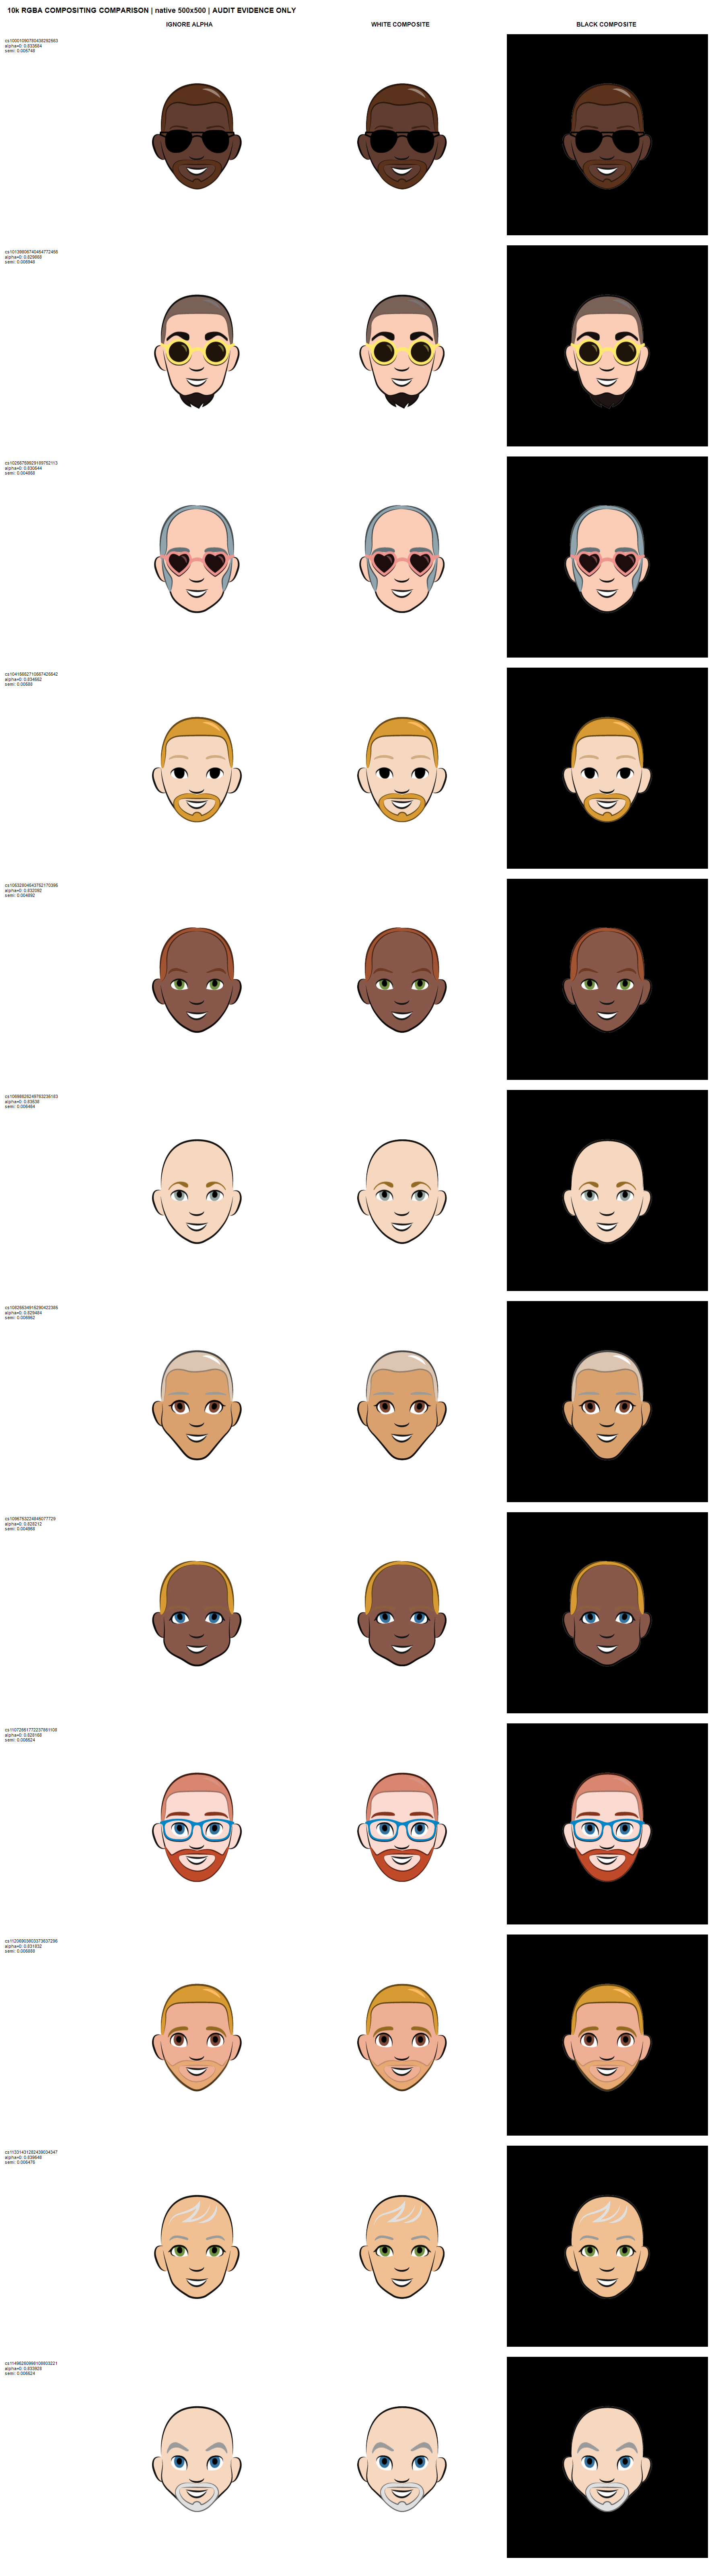

In [6]:
alpha = pd.read_csv(REPORTS / 'preprocessing_gate_00_alpha/alpha_summary.csv')
alpha_compact = alpha.loc[
    (alpha['section'] == 'coverage') & alpha['metric'].isin(['analyzed', 'unreadable', 'non_500x500']),
    ['dataset', 'metric', 'value', 'unit'],
]
display(alpha_compact.reset_index(drop=True))
alpha_figure = REPORTS / 'preprocessing_gate_00_alpha/10k_rgba_compositing_comparison.png'
if alpha_figure.is_file():
    display(Image(filename=str(alpha_figure), width=900))
else:
    print('Optional frozen compositing figure unavailable; numerical evidence remains above.')

## 7. Compositional split design

A random-only test asks whether new images resemble the training distribution. A compositional test asks whether known primitives can be generated in a **pairing never shown in TRAIN**. Candidate cells were selected only after simultaneous support checks across both official datasets: primitive survival, alternate partners greater than one, and no unintended missing pair cells.

`COMP_VAL` is available during development; `FINAL_OOD` is sealed for final assessment. `FINAL_OOD > COMP_VAL > ID` prevents a sample matching both panels from entering development validation. The same value-pair definitions are applied independently to 10k and 100k.

In [7]:
heldout = json.loads((DR01 / 'heldout_combinations.json').read_text(encoding='utf-8'))
rule_rows = []
for role_key, role_name in [('comp_val_definitions', 'COMP_VAL'), ('final_ood_definitions', 'FINAL_OOD')]:
    for rule in heldout[role_key]:
        rule_rows.append({
            'role': role_name, 'rule': rule['name'],
            'attribute pair': f"{rule['attribute_a']} × {rule['attribute_b']}",
            'held-out values': f"({rule['value_a']}, {rule['value_b']})",
        })
display(pd.DataFrame(rule_rows))
print('Precedence:', ' > '.join(heldout['precedence']))
print('ID policy:', heldout['id_split_proportions'], '| seed:', heldout['split_seed'])

,role,rule,attribute pair,held-out values
0,COMP_VAL,CV1,face_shape × glasses,"(0, 0)"
1,COMP_VAL,CV2,face_shape × hair_color,"(2, 3)"
2,COMP_VAL,CV3,glasses × face_color,"(7, 2)"
3,COMP_VAL,CV4,hair_color × face_color,"(2, 9)"
4,FINAL_OOD,OOD1,face_shape × glasses,"(2, 3)"
5,FINAL_OOD,OOD2,face_shape × hair_color,"(4, 6)"
6,FINAL_OOD,OOD3,glasses × face_color,"(10, 10)"
7,FINAL_OOD,OOD4,hair_color × face_color,"(0, 0)"


Precedence: FINAL_OOD > COMP_VAL > ID_POOL
ID policy: {'TRAIN': 0.9, 'ID_VAL': 0.05, 'ID_TEST': 0.05} | seed: 2026


## 8. Final split materialization and counts

The remaining ID pool is shuffled deterministically with seed 2026 and allocated 90/5/5 independently per dataset. Absolute counts differ by design. The checks below are recomputed from final manifests rather than copied from prose.

In [8]:
count_rows = []
for variant in VARIANTS:
    expected = split_summary['datasets'][variant]['final_split_counts']
    observed = {}
    seen_ids = set()
    for split in SPLITS:
        count = 0
        with (DR01 / variant / f'{split}.jsonl').open(encoding='utf-8') as handle:
            for line in handle:
                row = json.loads(line)
                assert row['image_id'] not in seen_ids
                seen_ids.add(row['image_id'])
                count += 1
        observed[split.upper()] = count
    assert len(seen_ids) == split_summary['datasets'][variant]['source_count']
    assert observed == expected
    count_rows.append({'dataset': variant, 'source': len(seen_ids), **observed})
display(pd.DataFrame(count_rows))
support = pd.DataFrame([
    {
        'dataset': variant,
        'post-holdout marginal minimum': split_summary['datasets'][variant]['post_holdout_marginal_minimum'],
        'partner-diversity minimum': split_summary['datasets'][variant]['post_holdout_partner_diversity']['minimum'],
        'unintended absent pair cells': split_summary['datasets'][variant]['unintended_absent_pair_count'],
    }
    for variant in VARIANTS
])
display(support)

,dataset,source,TRAIN,ID_VAL,ID_TEST,COMP_VAL,FINAL_OOD
0,10k,10000,8388,466,466,338,342
1,100k,100000,84011,4667,4667,3311,3344


,dataset,post-holdout marginal minimum,partner-diversity minimum,unintended absent pair cells
0,10k,366,6,0
1,100k,3723,6,0


## 9. Semantic mapping

Raw IDs remain authoritative. Only `glasses=11 → no_glasses` is an explicit official Google mapping. Other readable names are project-defined canonical labels derived from the visual audit; five neighboring face-fill colors remain marked ambiguous. `face_shape=1` deliberately remains neutral. Face-color names describe graphical fills, never demographic categories.

In [9]:
mapping_rows = []
for attribute in CANONICAL_ATTRIBUTE_ORDER:
    for value in semantic_mapping['attributes'][attribute]:
        mapping_rows.append({'attribute': attribute, **value})
mapping_df = pd.DataFrame(mapping_rows)
display(mapping_df[['attribute', 'raw_id', 'canonical_label', 'canonical_model_token', 'provenance_status']])
display(mapping_df.groupby('provenance_status').size().rename('value count').to_frame())

,attribute,raw_id,canonical_label,canonical_model_token,provenance_status
0,face_shape,0,pointed,face_shape_pointed,PROJECT_DEFINED_VISUALLY_CLEAR
1,face_shape,1,face_shape_1,face_shape_1,NEUTRAL_TOKEN
2,face_shape,2,oval,face_shape_oval,PROJECT_DEFINED_VISUALLY_CLEAR
3,face_shape,3,long,face_shape_long,PROJECT_DEFINED_VISUALLY_CLEAR
4,face_shape,4,round,face_shape_round,PROJECT_DEFINED_VISUALLY_CLEAR
5,face_shape,5,wide,face_shape_wide,PROJECT_DEFINED_VISUALLY_CLEAR
6,face_shape,6,rectangular,face_shape_rectangular,PROJECT_DEFINED_VISUALLY_CLEAR
7,glasses,0,oversized_glasses,glasses_oversized_glasses,PROJECT_DEFINED_VISUALLY_CLEAR
8,glasses,1,aviator_sunglasses,glasses_aviator_sunglasses,PROJECT_DEFINED_VISUALLY_CLEAR
9,glasses,2,cat_eye_glasses,glasses_cat_eye_glasses,PROJECT_DEFINED_VISUALLY_CLEAR


,value count
provenance_status,
NEUTRAL_TOKEN,1
OFFICIAL,1
PROJECT_DEFINED_AMBIGUOUS,5
PROJECT_DEFINED_VISUALLY_CLEAR,33


## 10. Deterministic caption grammar

Every image receives exactly one structured caption:

`avatar <face_shape_token> <glasses_token> <hair_color_token> <face_color_token>`

The five lexical tokens are lowercase, single-space separated, and fixed-order. Underscores keep multiword attribute values atomic; there are no paraphrases or omissions.

In [10]:
example = json.loads((DR01 / 'text/10k/train.jsonl').open(encoding='utf-8').readline())
regenerated = generate_caption(example)
assert regenerated == example['caption']
assert caption_tokens(example) == regenerated.split()
display(pd.DataFrame([{
    'raw IDs': {name: example[name] for name in CANONICAL_ATTRIBUTE_ORDER},
    'caption': example['caption'],
    'serialized tokens': example['tokens'],
    'token IDs': example['token_ids'],
    'attention mask': example['attention_mask'],
}]))

,raw IDs,caption,serialized tokens,token IDs,attention mask
0,"{'face_shape': 4, 'glasses': 0, 'hair_color': 9, 'face_color': 10}",avatar face_shape_round glasses_oversized_glasses hair_color_silver face_color_pale_pink,"[<bos>, avatar, face_shape_round, glasses_oversized_glasses, hair_color_silver, face_c...","[1, 4, 21, 29, 44, 12, 2]","[1, 1, 1, 1, 1, 1, 1]"


## 11. TRAIN-only tokenizer and vocabulary

The tokenizer lowercases, normalizes whitespace, and splits only on whitespace. IDs are deterministic: `0 <pad>`, `1 <bos>`, `2 <eos>`, `3 <unk>`, followed by lexical tokens sorted lexicographically. Vocabulary discovery and frequency counting use TRAIN captions only; non-TRAIN captions cannot add tokens. The serialized length is fixed at 7 (`<bos>` + five lexical tokens + `<eos>`), so canonical captions require no padding.

In [11]:
vocabs = {variant: json.loads((DR01 / f'text/{variant}/vocab.json').read_text(encoding='utf-8')) for variant in VARIANTS}
vocab_rows = []
lexical_sets = {}
for variant, vocab in vocabs.items():
    assert vocab['source_split'] == 'TRAIN'
    assert [vocab['token_to_id'][token] for token in SPECIAL_TOKENS] == [0, 1, 2, 3]
    lexical_sets[variant] = set(vocab['token_to_id']) - set(SPECIAL_TOKENS)
    vocab_rows.append({'dataset': variant, 'total tokens': vocab['vocab_size'], 'special': 4, 'lexical': len(lexical_sets[variant]), 'source': vocab['source_split']})
display(pd.DataFrame(vocab_rows))
comparison = {
    'lexical intersection': len(lexical_sets['10k'] & lexical_sets['100k']),
    'unique to 10k': sorted(lexical_sets['10k'] - lexical_sets['100k']),
    'unique to 100k': sorted(lexical_sets['100k'] - lexical_sets['10k']),
    'equal (observed, not imposed)': lexical_sets['10k'] == lexical_sets['100k'],
}
display(pd.DataFrame([comparison]))

,dataset,total tokens,special,lexical,source
0,10k,45,4,41,TRAIN
1,100k,45,4,41,TRAIN


,lexical intersection,unique to 10k,unique to 100k,"equal (observed, not imposed)"
0,41,[],[],True


## 12. Leakage and reproducibility checks

These lightweight checks scan every enriched manifest. They regenerate captions through the reusable project module, reconstruct tokenization from each serialized TRAIN vocabulary, and confirm zero OOV/`<unk>` without altering vocabulary state. Split construction and text materialization logic remain in `src/tiny_avatar_diffusion/`; implementation is not duplicated here.

In [12]:
leakage_rows = []
for variant in VARIANTS:
    token_to_id = vocabs[variant]['token_to_id']
    tokenizer = WhitespaceTokenizer(token_to_id, max_length=7)
    lexical_vocab = set(token_to_id) - set(SPECIAL_TOKENS)
    for split in SPLITS:
        rows = oov = unknowns = 0
        with (DR01 / f'text/{variant}/{split}.jsonl').open(encoding='utf-8') as handle:
            for line in handle:
                row = json.loads(line)
                regenerated = generate_caption(row)
                assert regenerated == row['caption']
                encoded = tokenizer.encode(regenerated)
                assert encoded.tokens == row['tokens']
                assert encoded.token_ids == row['token_ids']
                assert encoded.attention_mask == row['attention_mask']
                oov += len(set(regenerated.split()) - lexical_vocab)
                unknowns += encoded.token_ids.count(UNK_ID)
                rows += 1
        leakage_rows.append({'dataset': variant, 'split': split.upper(), 'rows': rows, 'OOV tokens': oov, '<unk> IDs': unknowns, 'deterministic regeneration': True})
leakage_df = pd.DataFrame(leakage_rows)
display(leakage_df)
assert (leakage_df[['OOV tokens', '<unk> IDs']] == 0).all().all()
assert split_summary['cross_dataset_consistency']['all_checks_passed']
print('PASS — split integrity, TRAIN-only vocabulary coverage, zero OOV, zero <unk>, and deterministic regeneration.')

,dataset,split,rows,OOV tokens,<unk> IDs,deterministic regeneration
0,10k,TRAIN,8388,0,0,True
1,10k,ID_VAL,466,0,0,True
2,10k,ID_TEST,466,0,0,True
3,10k,COMP_VAL,338,0,0,True
4,10k,FINAL_OOD,342,0,0,True
5,100k,TRAIN,84011,0,0,True
6,100k,ID_VAL,4667,0,0,True
7,100k,ID_TEST,4667,0,0,True
8,100k,COMP_VAL,3311,0,0,True
9,100k,FINAL_OOD,3344,0,0,True


PASS — split integrity, TRAIN-only vocabulary coverage, zero OOV, zero <unk>, and deterministic regeneration.


# DR01 FINAL DECISIONS

| Component | Frozen decision |
|---|---|
| Dataset | Official Google Cartoon Set 10k + 100k |
| Main attributes | `face_shape`, `glasses`, `hair_color`, `face_color` |
| Main resolution | 32×32 |
| Optional resolution | 100k@64 |
| Preprocessing | RGBA → white composite → RGB → bilinear antialiased 32×32 → `[0,1]` → `[-1,1]` |
| Main comparison | 10k@32 versus 100k@32 |
| Split | 4 COMP_VAL pairs + 4 FINAL_OOD pairs; `FINAL_OOD > COMP_VAL > ID` |
| ID allocation | 90% TRAIN / 5% ID_VAL / 5% ID_TEST; seed 2026 |
| Text | Deterministic five-token structured captions |
| Tokenizer | Whitespace word-level; TRAIN-only vocabulary |
| Vocabulary | 45 tokens = 4 special + 41 lexical; equality across scales observed, not imposed |
| Sequence | `max_length=7`; zero OOV and zero `<unk>` on every canonical split |

DR01 is complete. Model architecture, text encoder, diffusion process, training, and evaluation implementation belong to subsequent decision records.

## 14. Canonical handoff to subsequent stages

Later model stages should consume the versioned artifacts below—not exploratory audit reports. Raw split manifests preserve IDs and source-image references; enriched text manifests add caption/tokens/IDs/masks. Dataset loaders must implement the frozen image preprocessing decision above.

In [13]:
handoff = [
    ('Split protocol', 'data/processed/dr01_v1/heldout_combinations.json'),
    ('Split validation/counts', 'data/processed/dr01_v1/split_summary.json'),
    ('Raw-ID manifests', 'data/processed/dr01_v1/{10k,100k}/*.jsonl'),
    ('Semantic mapping', 'data/processed/dr01_v1/semantic_mapping.json'),
    ('Guided-prompt contract', 'data/processed/dr01_v1/ui_prompt_contract.json'),
    ('Caption/token manifests', 'data/processed/dr01_v1/text/{10k,100k}/*.jsonl'),
    ('Per-scale TRAIN vocabulary', 'data/processed/dr01_v1/text/{10k,100k}/vocab.json'),
    ('Tokenizer configuration', 'data/processed/dr01_v1/text/{10k,100k}/tokenizer_config.json'),
    ('Reusable implementation', 'src/tiny_avatar_diffusion/{semantic_mapping,captions,tokenizer,dr01_split,dr01_text}.py'),
]
display(pd.DataFrame(handoff, columns=['Purpose', 'Canonical project-relative path']))
required_files = [
    DR01 / 'heldout_combinations.json', DR01 / 'split_summary.json',
    DR01 / 'semantic_mapping.json', DR01 / 'ui_prompt_contract.json',
]
assert all(path.is_file() for path in required_files)
print('Canonical handoff present. Exploratory reports are not runtime dependencies for later model stages.')

,Purpose,Canonical project-relative path
0,Split protocol,data/processed/dr01_v1/heldout_combinations.json
1,Split validation/counts,data/processed/dr01_v1/split_summary.json
2,Raw-ID manifests,"data/processed/dr01_v1/{10k,100k}/*.jsonl"
3,Semantic mapping,data/processed/dr01_v1/semantic_mapping.json
4,Guided-prompt contract,data/processed/dr01_v1/ui_prompt_contract.json
5,Caption/token manifests,"data/processed/dr01_v1/text/{10k,100k}/*.jsonl"
6,Per-scale TRAIN vocabulary,"data/processed/dr01_v1/text/{10k,100k}/vocab.json"
7,Tokenizer configuration,"data/processed/dr01_v1/text/{10k,100k}/tokenizer_config.json"
8,Reusable implementation,"src/tiny_avatar_diffusion/{semantic_mapping,captions,tokenizer,dr01_split,dr01_text}.py"


Canonical handoff present. Exploratory reports are not runtime dependencies for later model stages.


## Execution environment

This final cell records the environment used for the clean notebook execution. Runtime is measured from the first setup cell; no training or raw-archive mutation occurs.

In [14]:
environment = pd.DataFrame([
    {'component': 'Python', 'version': platform.python_version()},
    {'component': 'pandas', 'version': metadata.version('pandas')},
    {'component': 'nbformat', 'version': metadata.version('nbformat')},
    {'component': 'nbconvert', 'version': metadata.version('nbconvert')},
    {'component': 'IPython', 'version': metadata.version('ipython')},
])
display(environment)
elapsed = time.perf_counter() - NOTEBOOK_START
print(f'Notebook in-kernel execution time: {elapsed:.3f} seconds')
print('Execution status: PASS — all cells completed; no model training triggered.')

,component,version
0,Python,3.12.4
1,pandas,2.2.2
2,nbformat,5.9.2
3,nbconvert,7.10.0
4,IPython,8.25.0


Notebook in-kernel execution time: 2.790 seconds
Execution status: PASS — all cells completed; no model training triggered.
